# Conformity, and pixels in the plane you ask for

A mesh is **conforming** when every two cells meet in a whole shared face, edge or corner, with the same point ids on both sides. `check_conformity` reports where that fails:

- a **hanging node**: a point on a volume cell's face or edge that the cell does not use;
- a **T-junction**: the same on the edge of a 2-D cell;
- a **partial overlap**: two unmatched facets in one plane that overlap without being one facet;
- an **unwelded** pair: two coincident facets with different point ids.

It flags the hanging points in `conformity:hanging` and says which `find_interface` mode suits the mesh: `"conforming"`, `"weld"` or `"proximity"`. The cases here are harder than a sphere: the **Stanford bunny** (`example/Bunny.stl`, 112 402 triangles of a scan), meshes from `refine`, and two parts meshed apart. The last section voxelizes a scanned cross-section in the plane you choose with `voxelize(..., plane=...)`.

It is also a CLI verb (`meshioplusplus check-conformity in.vtu [out.vtu] --json`, exit 1 when not conforming), a `CheckConformity` pipeline gate and an MCP tool.

In [1]:
import os
import tempfile
import time

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

import meshioplusplus as mp

try:
    import pyvista as pv
    pv.OFF_SCREEN = True
    pv.set_jupyter_backend('static')
except Exception:  # pragma: no cover - PyVista is optional
    pv = None

# The Stanford bunny shipped with the examples ("Stanford Bunny -- Digitized!" by
# MakerBot, CC BY 3.0, see example/README.md): 112 402 triangles, closed.
BUNNY = os.path.join(os.path.dirname(os.getcwd()), 'Bunny.stl')


def gl_available():
    """Probe off-screen GL in a child process: a missing GL stack can kill the
    interpreter outright, which no try/except in this one would survive."""
    if pv is None:
        return False
    import subprocess, sys
    probe = ('import pyvista as pv; pv.OFF_SCREEN = True; pl = pv.Plotter(off_screen=True); '
             'pl.add_mesh(pv.Sphere()); pl.screenshot(return_img=True)')
    try:
        return subprocess.run([sys.executable, '-c', probe], capture_output=True,
                              timeout=120).returncode == 0
    except Exception:
        return False


GL = gl_available()
print('PyVista rendering' if GL else 'matplotlib fallback (no off-screen GL)')


def to_pyvista(mesh):
    with tempfile.NamedTemporaryFile(suffix='.vtu', delete=False) as f:
        tmp = f.name
    try:
        mp.write(tmp, mesh)
        return pv.read(tmp)
    finally:
        os.unlink(tmp)


def show(img, title):
    plt.figure(figsize=(9, 7)); plt.imshow(img); plt.axis('off'); plt.title(title); plt.show()


def boundary_faces(mesh, keep=None):
    """The faces used once by the kept cells (all cells by default), as point arrays."""
    pts = np.asarray(mesh.points, dtype=float)
    if pts.shape[1] == 2:
        pts = np.column_stack([pts, np.zeros(len(pts))])
    seen = {}
    start = 0
    for cb in mesh.cells:
        conn = np.asarray(cb.data)
        faces = {'tetra': [(0, 1, 3), (1, 2, 3), (2, 0, 3), (0, 2, 1)],
                 'hexahedron': [(0, 3, 2, 1), (4, 5, 6, 7), (0, 1, 5, 4), (1, 2, 6, 5),
                                (2, 3, 7, 6), (3, 0, 4, 7)],
                 'triangle': [(0, 1, 2)], 'quad': [(0, 1, 2, 3)]}.get(cb.type, [])
        for c in range(len(conn)):
            if keep is not None and not keep[start + c]:
                continue
            for f in faces:
                ids = conn[c, list(f)]
                key = tuple(sorted(ids))
                seen[key] = None if key in seen else ids
        start += len(conn)
    return [pts[f] for f in seen.values() if f is not None]


def render_clip(mesh, title, scalars=None, cmap='viridis', normal='y', origin=None,
                points=None, edges=True, camera=(20, 25)):
    """A volume mesh cut open by a plane (y by default), optionally coloured by a
    cell array and with marked points: PyVista when GL is available, else the
    boundary faces of the kept half in a matplotlib 3-D collection."""
    p = np.asarray(mesh.points, dtype=float)
    origin = p.mean(axis=0) if origin is None else origin
    ax_n = 'xyz'.index(normal)
    if GL:
        grid = to_pyvista(mesh)
        half = grid.clip(normal=normal, origin=origin, crinkle=True)
        if points is not None and len(points):
            # Only the marks in the kept half (whole cells, so up to its far
            # face): the others would float in front of the cut.
            points = np.asarray(points, dtype=float)
            points = points[points[:, ax_n] <= half.bounds[2 * ax_n + 1]]
        pl = pv.Plotter(off_screen=True, window_size=(900, 700))
        pl.add_mesh(half, scalars=scalars, cmap=cmap, show_edges=edges,
                    edge_color='#333333', line_width=0.3, color='#c9d6df')
        if points is not None and len(points):
            pl.add_points(np.asarray(points, dtype=float), color='crimson', point_size=5,
                          render_points_as_spheres=True)
        pl.view_xz(negative=True)
        pl.camera.elevation, pl.camera.azimuth = camera
        img = pl.screenshot(return_img=True)
        pl.close()
        show(img, title)
        return
    if points is not None and len(points):
        points = np.asarray(points, dtype=float)
        points = points[points[:, ax_n] <= origin[ax_n]]
    keep = []
    for cb in mesh.cells:
        c = p[np.asarray(cb.data)].mean(axis=1)[:, ax_n]
        keep.extend(c < origin[ax_n])
    polys = boundary_faces(mesh, keep)
    fig = plt.figure(figsize=(8, 7))
    ax = fig.add_subplot(projection='3d')
    ax.add_collection3d(Poly3DCollection(polys, facecolors='#c9d6df', edgecolors='k',
                                         linewidths=0.1))
    if points is not None and len(points):
        q = np.asarray(points)
        ax.scatter(q[:, 0], q[:, 1], q[:, 2], c='crimson', s=2)
    ax.set_xlim(p[:, 0].min(), p[:, 0].max()); ax.set_ylim(p[:, 1].min(), p[:, 1].max())
    ax.set_zlim(p[:, 2].min(), p[:, 2].max()); ax.set_box_aspect(np.ptp(p, axis=0))
    ax.view_init(elev=18, azim=62); ax.set_axis_off(); ax.set_title(title)
    plt.show()


def show_report(report, keys):
    for k in keys:
        v = report[k]
        print(f'{k:32s} {v:.4g}' if isinstance(v, float) else f'{k:32s} {v}')
    for w in report.get('warnings', []):
        print('warning:', w)


PyVista rendering


## An octree of the bunny

`octree` puts fine leaves where the skin is. With `transition="hanging"` (the default) a fine leaf meets a coarse one with **hanging nodes**, flagged in `octree:hanging`; `"polyhedra"` and `"templates"` are conforming. `check_conformity` finds the same nodes from the geometry alone.

In [2]:
bunny = mp.read(BUNNY)
print(bunny)
kw = dict(max_level=6, fill='inside', padding_relative=0.02)
for transition in ('hanging', 'polyhedra', 'templates'):
    t0 = time.perf_counter()
    tree, tree_rep = mp.octree(bunny, transition=transition, return_report=True, **kw)
    checked, rep = mp.check_conformity(tree, return_report=True)
    print(f"{transition:10s} {sum(len(c.data) for c in tree.cells):7d} cells: "
          f"octree:hanging {tree_rep['num_hanging']:5d}, check_conformity hanging nodes "
          f"{rep['num_hanging_nodes']:5d}, partial overlaps {rep['num_partial_overlaps']:5d}, "
          f"mode {rep['interface_mode']!r} ({time.perf_counter() - t0:.1f} s)")
    if transition == 'hanging':
        hanging_tree, hanging_flags = checked, np.asarray(checked.point_data['conformity:hanging'])
same = np.array_equal(hanging_flags != 0,
                      np.asarray(hanging_tree.point_data['octree:hanging']).reshape(-1) != 0)
print('conformity:hanging marks exactly the octree:hanging points:', same)

<meshio++ mesh object>
  Number of points: 56203
  Number of cells:
    triangle: 112402


hanging      13870 cells: octree:hanging  8720, check_conformity hanging nodes  8720, partial overlaps 11451, mode 'proximity' (0.9 s)


polyhedra    13870 cells: octree:hanging     0, check_conformity hanging nodes     0, partial overlaps     0, mode 'conforming' (1.0 s)


templates    63060 cells: octree:hanging     0, check_conformity hanging nodes     0, partial overlaps     0, mode 'conforming' (1.1 s)
conformity:hanging marks exactly the octree:hanging points: True


2026-10-27 17:51:57.499 (   5.581s) [    7FE804555080]vtkXOpenGLRenderWindow.:1452  WARN| bad X server connection. DISPLAY=


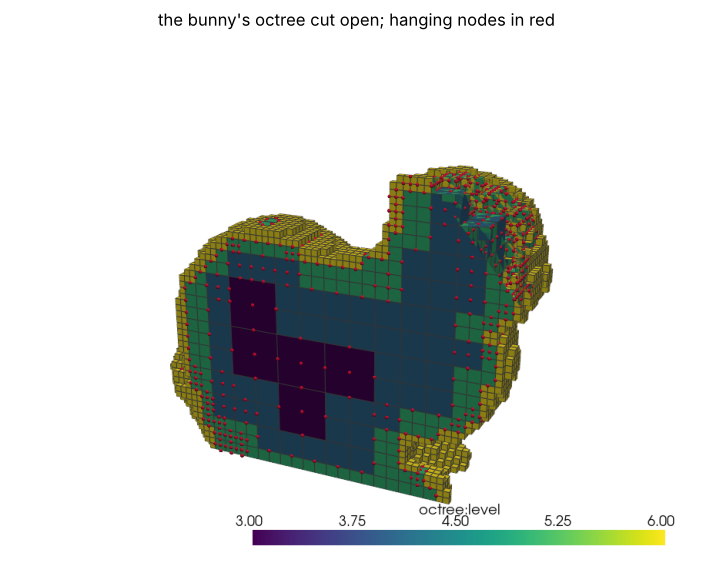

In [3]:
pts = np.asarray(hanging_tree.points)
render_clip(hanging_tree, 'the bunny\'s octree cut open; hanging nodes in red',
            points=pts[hanging_flags != 0], scalars='octree:level')

## Refinement: balanced, red-green, and undone

`refine(closure="balanced")` keeps hanging nodes on purpose and lists them in `refine:hanging`; the `"redgreen"` and `"propagate"` closures are conforming. `undo_green` restores the coarse parents of the green cells, and the red children beside them are left with nodes hanging on the parents' edges: a T-junction in 2-D, and `refine:hanging` is gone, so `check_conformity` is how they are found.

In [4]:
grid = mp.box((6, 6, 6), (6, 6, 6))
centre = [i for i in range(216) if i in (86, 87, 92, 93, 122, 123, 128, 129)]
for closure in ('balanced', 'redgreen', 'propagate'):
    out = mp.refine(grid, cells=centre, closure=closure)
    _, rep = mp.check_conformity(out, return_report=True)
    want = int(np.asarray(out.point_data['refine:hanging']).sum()) if 'refine:hanging' in out.point_data else 0
    print(f"{closure:10s}: {sum(len(c.data) for c in out.cells):5d} cells, hanging nodes "
          f"{rep['num_hanging_nodes']:3d} (refine:hanging {want:3d}), conforming {rep['conforming']}")

coarse = mp.rectangle((6, 6), (6, 6), cell_type='triangle', split='up')
fine = mp.refine(coarse, cells=[30, 31, 40, 41], record_hierarchy=True, record_levels=True)
undone = mp.undo_green(coarse, fine)
flagged, rep = mp.check_conformity(undone, return_report=True)
print('after undo_green:', rep['num_t_junctions'], 'T-junctions, mode', rep['interface_mode'])

balanced  :   272 cells, hanging nodes  72 (refine:hanging  72), conforming False
redgreen  :   512 cells, hanging nodes   0 (refine:hanging   0), conforming True
propagate :  1728 cells, hanging nodes   0 (refine:hanging   0), conforming True
after undo_green: 8 T-junctions, mode proximity


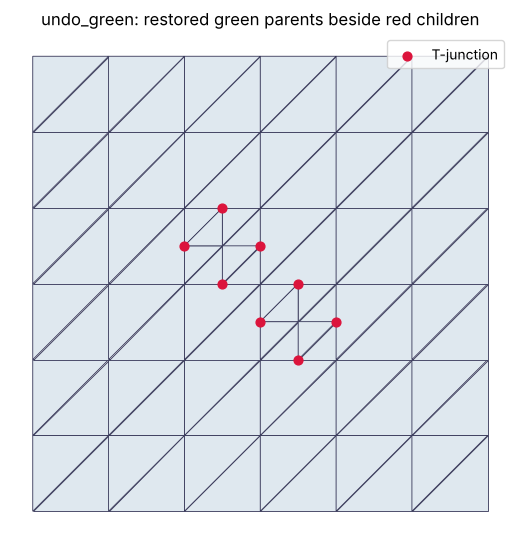

In [5]:
flags = np.asarray(flagged.point_data['conformity:hanging'])
pts = np.asarray(undone.points)
fig, ax = plt.subplots(figsize=(6.5, 6.5))
for cb in undone.cells:
    for tri in np.asarray(cb.data):
        ax.fill(*pts[tri, :2].T, facecolor='#dfe8ef', edgecolor='#335', lw=0.6)
ax.scatter(*pts[flags != 0, :2].T, c='crimson', s=40, zorder=3, label='T-junction')
ax.set_aspect('equal'); ax.set_axis_off(); ax.legend(loc='upper right')
ax.set_title('undo_green: restored green parents beside red children')
plt.show()

## Two parts meshed apart

Two blocks meshed separately meet on a face. When their nodes coincide but are not shared, the facets are **unwelded** and the advice is `"weld"`: merge the points (`clean(weld=True)` or `merge(weld=True)`), after which they conform. When one block is finer the nodes do not match at all: the facets **partly overlap**, the fine block's nodes hang on the coarse faces, and the advice is `"proximity"`, the `find_interface` mode that pairs facets by projection.

In [6]:
left = mp.box((4, 4, 4), (1.0, 1.0, 1.0))
right_same = mp.transform(mp.box((4, 4, 4), (1.0, 1.0, 1.0)), translate=(1.0, 0.0, 0.0))
right_fine = mp.transform(mp.box((7, 7, 7), (1.0, 1.0, 1.0)), translate=(1.0, 0.0, 0.0))
for name, right in (('same lattice', right_same), ('finer lattice', right_fine)):
    pair = mp.merge([left, right], weld=False)
    _, rep = mp.check_conformity(pair, return_report=True)
    print(f"{name:13s}: unwelded {rep['num_unwelded_facets']:3d}, partial overlaps "
          f"{rep['num_partial_overlaps']:3d}, hanging {rep['num_hanging_nodes']:3d} -> {rep['interface_mode']!r}")
welded = mp.clean(mp.merge([left, right_same], weld=False), weld=True)
print('welded:', mp.check_conformity(welded, return_report=True)[1]['interface_mode'])

same lattice : unwelded  16, partial overlaps   0, hanging   0 -> 'weld'
finer lattice: unwelded   0, partial overlaps 100, hanging  81 -> 'proximity'
welded: conforming


## Pixels of a scanned cross-section, in its own plane

`voxelize` with a two-entry `resolution` makes `quad` pixels around a planar skin. By default the plane is the axis along which the skin has zero extent, falling back to `xy`. A slice of a scan is planar only up to the cut's own tilt, so `plane` names it. Here the bunny is cut by a plane tilted half a degree off `y = const`: no axis is exactly flat, `"auto"` falls back to `xy` and sees an edge-on sliver, and `plane="xz"` sees the cross-section.

In [7]:
tilt = np.radians(0.5)
section = mp.slice(bunny, origin=(30.0, 0.0, 55.0), normal=(0.0, np.cos(tilt), np.sin(tilt)))
print(section, 'y range', np.ptp(np.asarray(section.points)[:, 1]))
images = {}
for plane in ('auto', 'xz'):
    pix, rep = mp.voxelize(section, resolution=(160, 160), padding_relative=0.03,
                           fill='inside', plane=plane, return_report=True)
    images[plane] = (pix, rep)
    print(f"plane={plane!r}: {rep['num_occupied']} of {rep['dims'][0] * rep['dims'][1]} pixels inside")

<meshio++ mesh object>
  Number of points: 880
  Number of cells:
    line: 880 y range 0.7978413788658836
plane='auto': 1427 of 25600 pixels inside
plane='xz': 14825 of 25600 pixels inside


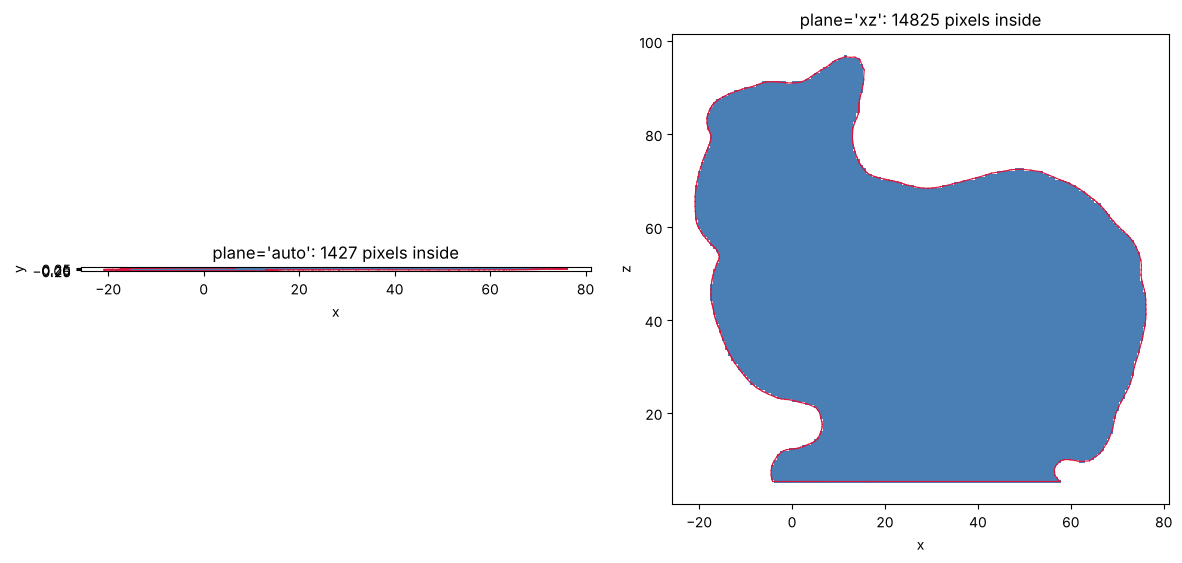

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, (plane, (pix, rep)) in zip(axes, images.items()):
    p = np.asarray(pix.points)
    u, v = (0, 1) if plane == 'auto' else (0, 2)
    for cb in pix.cells:
        quads = p[np.asarray(cb.data)][:, :, [u, v]]
        for q in quads:
            ax.fill(*q.T, facecolor='#4a7fb5', edgecolor='none')
    s = np.asarray(section.points)
    for cb in section.cells:
        for a, b in np.asarray(cb.data):
            ax.plot(s[[a, b], u], s[[a, b], v], color='crimson', lw=0.8)
    ax.set_aspect('equal'); ax.set_title(f"plane={plane!r}: {rep['num_occupied']} pixels inside")
    ax.set_xlabel('xyz'[u]); ax.set_ylabel('xyz'[v])
plt.tight_layout(); plt.show()

## Where to go next

- [Conformity check](../../doc/check_conformity.md): the rules, the tolerance, the CLI, the pipeline and the bindings.
- [Octree](../../doc/octree.md) and [voxelize](../../doc/voxelize.md#2-d-pixels) for the meshes above; `41_octree_mesh.ipynb` and `44_octree_mesh_real_skins.ipynb` for volume meshes of skins.